# 02 - Preprocessing (KDD stage 2) - real data
Goals: confirm the data is clean, put units on the project's convention, and decide - explicitly -
what **not** to change.

Decisions made in this notebook:
1. **No imputation.** Notebook 01 found no gaps and no missing values, so nothing is filled. The code asserts
   this rather than assuming it, so a future file with gaps fails loudly instead of being silently patched.
2. **No clipping or outlier removal on rainfall.** Rainfall is zero-inflated and heavy-tailed; the extreme days
   *are* the events we want to predict.
3. Wind speed converted from km/h to m/s (the project convention in `backend/notebooks/common.py`).

In [1]:
import sys
from pathlib import Path


def _find_helpers():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base, base / "notebooks" / "real_data"):
            if (cand / "weather_data.py").is_file():
                return cand
    raise SystemExit("weather_data.py not found. Open this notebook from inside the repository.")


sys.path.insert(0, str(_find_helpers()))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import weather_data as wd

ROOT = wd.find_root()
OUT = wd.out_dir(ROOT)
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
COLORS = {"KZN-ETHEKWINI": "#2a6fbb", "MP-EHLANZENI": "#d9822b"}
LABEL = {rid: s["label"] for rid, s in wd.STATIONS.items()}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(OUT / "weather_selected.csv", parse_dates=["date"])
df = df.sort_values(["region_id", "date"]).reset_index(drop=True)
print("loaded", df.shape, "from", (OUT / "weather_selected.csv").relative_to(ROOT))

loaded (790, 7) from notebooks/real_data/outputs/weather_selected.csv


## 1. Checks that must pass

In [2]:
assert df.isna().sum().sum() == 0, "missing values found: add an explicit gap strategy before continuing"
for rid, g in df.groupby("region_id"):
    full = pd.date_range(g["date"].min(), g["date"].max(), freq="D")
    assert len(full) == len(g) and not g["date"].duplicated().any(), f"{rid}: calendar not complete"
print("OK: no missing values, every region has a complete daily calendar")

rows = []
for col, (lo, hi) in wd.BOUNDS.items():
    bad = int(((df[col] < lo) | (df[col] > hi)).sum())
    rows.append({"variable": col, "allowed_min": lo, "allowed_max": hi,
                 "observed_min": df[col].min(), "observed_max": df[col].max(), "rows_out_of_range": bad})
ranges = pd.DataFrame(rows)
assert ranges["rows_out_of_range"].sum() == 0
ranges

OK: no missing values, every region has a complete daily calendar


,variable,allowed_min,allowed_max,observed_min,observed_max,rows_out_of_range
0,rainfall_mm,0,1000,0.0,117.8,0
1,temperature_c,-20,55,9.3,27.6,0
2,humidity_pct,0,100,28.0,93.0,0
3,pressure_hpa,850,1100,1005.8,1037.5,0
4,wind_kmh,0,300,6.6,47.7,0


## 2. Unit conversion

In [3]:
df["wind_ms"] = (df["wind_kmh"] / 3.6).round(3)
df = df.drop(columns="wind_kmh")
df.groupby("region_id")["wind_ms"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
region_id,,,,,,,,
KZN-ETHEKWINI,395.0,6.09,1.95,2.44,4.49,5.94,7.22,13.25
MP-EHLANZENI,395.0,3.67,0.73,1.83,3.17,3.61,4.11,6.67


## 3. Why rainfall is left untouched
Rainfall is dominated by dry days with a long tail of rare, very wet days. Classical outlier rules
(e.g. "drop values beyond 1.5 x IQR") would delete exactly the extreme days we need.

,dry (<1 mm),10 mm or more,20 mm or more
region_id,,,
Durban (KwaZulu-Natal),70.1,8.6,4.1
Mbombela (Mpumalanga),61.5,6.1,2.0


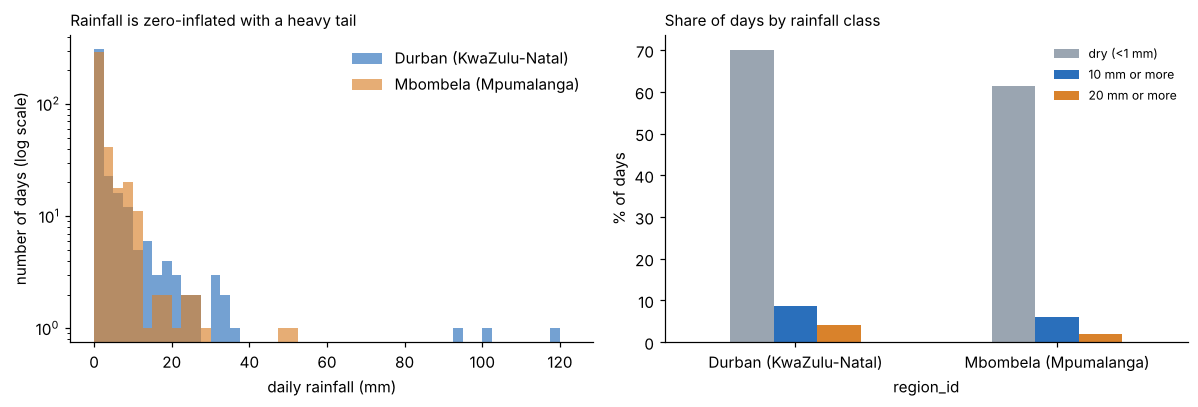

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for rid, g in df.groupby("region_id"):
    axes[0].hist(g["rainfall_mm"], bins=np.arange(0, 125, 2.5), alpha=0.65, color=COLORS[rid], label=LABEL[rid])
axes[0].set_yscale("log")
axes[0].set_xlabel("daily rainfall (mm)")
axes[0].set_ylabel("number of days (log scale)")
axes[0].set_title("Rainfall is zero-inflated with a heavy tail", loc="left", fontsize=10)
axes[0].legend(frameon=False)

dry = df.groupby("region_id")["rainfall_mm"].apply(lambda s: (s < 1).mean()).rename(LABEL)
shares = pd.DataFrame({
    "dry (<1 mm)": df.groupby("region_id")["rainfall_mm"].apply(lambda s: (s < 1).mean()),
    "10 mm or more": df.groupby("region_id")["rainfall_mm"].apply(lambda s: (s >= 10).mean()),
    "20 mm or more": df.groupby("region_id")["rainfall_mm"].apply(lambda s: (s >= 20).mean()),
}).rename(index=LABEL) * 100
shares.plot(kind="bar", ax=axes[1], color=["#9aa5b1", "#2a6fbb", "#d9822b"], rot=0)
axes[1].set_ylabel("% of days")
axes[1].set_title("Share of days by rainfall class", loc="left", fontsize=10)
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "02_rainfall_distribution.png", dpi=130)
plt.show()
shares.round(1)

## 4. Relationships between variables (Pearson correlation, per region)

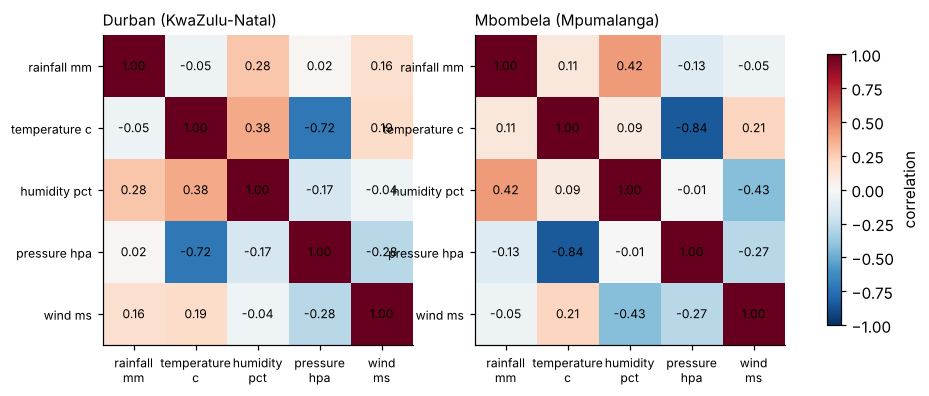

In [5]:
cols = ["rainfall_mm", "temperature_c", "humidity_pct", "pressure_hpa", "wind_ms"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (rid, g) in zip(axes, df.groupby("region_id")):
    c = g[cols].corr()
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), [x.replace("_", "\n") for x in cols], fontsize=8)
    ax.set_yticks(range(len(cols)), [x.replace("_", " ") for x in cols], fontsize=8)
    for (i, j), v in np.ndenumerate(c.to_numpy()):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(LABEL[rid], loc="left", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label="correlation")
fig.savefig(FIG / "02_correlations.png", dpi=130, bbox_inches="tight")
plt.show()

Humidity moves with rainfall on the same day, which is expected. Same-day correlations are not a
forecast, though - notebook 03 builds features from **today and earlier** to predict **tomorrow**.

## 5. Save the cleaned table

In [6]:
clean_path = OUT / "weather_clean.csv"
df.to_csv(clean_path, index=False)
meta_path = OUT / "weather_clean.meta.json"
meta_path.write_text(json.dumps({
    "data_kind": "real", "rows": int(len(df)),
    "sha256": {clean_path.name: wd.sha256_file(clean_path)},
    "steps": ["asserted no gaps / duplicates", "wind km/h -> m/s", "rainfall untouched"],
}, indent=2), encoding="utf-8")
print("saved", clean_path.relative_to(ROOT), df.shape)
df.dtypes.to_frame("dtype")

saved notebooks/real_data/outputs/weather_clean.csv (790, 7)


,dtype
region_id,str
date,datetime64[us]
rainfall_mm,float64
temperature_c,float64
humidity_pct,int64
pressure_hpa,float64
wind_ms,float64
